# 鸢尾花分类：基于 KNN 的机器学习入门案例

> 一个从数据探索、特征标准化到模型训练、评估与参数优化的完整机器学习实践。

本项目使用 Scikit-learn 内置的 Iris（鸢尾花）数据集，训练 **K-近邻算法（K-Nearest Neighbors，KNN）**，根据花萼和花瓣的测量数据预测鸢尾花的类别。

**适合读者：** 机器学习初学者，已经了解 Python 基础语法，希望通过一个小项目理解经典监督学习流程。

---

## 学习目标

完成本案例后，你将能够：

1. 使用 Scikit-learn 加载数据集，并理解特征（Feature）与标签（Label）。
2. 使用 Pandas 查看数据，使用 Seaborn / Matplotlib 做基础可视化。
3. 理解训练集、测试集的作用，以及为什么要分层抽样。
4. 理解归一化（Min-Max Scaling）和标准化（Standardization）的区别。
5. 使用 KNN 完成分类模型的训练与预测。
6. 使用准确率、混淆矩阵和分类报告评估模型。
7. 使用交叉验证和 GridSearchCV 搜索更合适的 K 值。

## 项目流程

```text
加载数据
   ↓
数据检查与可视化
   ↓
划分训练集 / 测试集
   ↓
特征标准化
   ↓
训练 KNN 模型
   ↓
预测与模型评估
   ↓
K 值调优（扩展）
```

**注意：** 本案例使用固定随机种子，便于复现结果。模型表现会受到数据划分方式、参数设置和软件版本等因素影响。

## 1. 认识问题与数据集

### 1.1 任务定义

这是一个典型的**监督学习（Supervised Learning）中的多分类问题**。

- 输入：一朵鸢尾花的 4 个测量特征。
- 输出：鸢尾花所属的 3 个类别之一。
- 任务：学习特征与类别之间的关系，并对未见过的数据进行分类。

### 1.2 四个输入特征

| 特征 | 中文含义 | 单位 |
|---|---|---|
| sepal length | 花萼长度 | cm |
| sepal width | 花萼宽度 | cm |
| petal length | 花瓣长度 | cm |
| petal width | 花瓣宽度 | cm |

数据集包含三个类别：`setosa`、`versicolor` 和 `virginica`。

## 2. 导入工具包

本案例主要使用：

- **NumPy**：数值计算。
- **Pandas**：表格数据处理。
- **Matplotlib / Seaborn**：数据可视化。
- **Scikit-learn**：数据集、数据预处理、模型训练和模型评估。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

# 绘图基础设置
sns.set_theme(style="whitegrid")
plt.rcParams["axes.unicode_minus"] = False

# 固定随机种子，增强实验的可复现性
RANDOM_STATE = 42

## 3. 加载数据集与初步认识

### 3.1 加载 Iris 数据集

`load_iris()` 是 Scikit-learn 提供的内置数据集加载函数。

返回的数据对象中常用字段：

- `data`：特征矩阵，每一行代表一个样本，每一列代表一个特征。
- `target`：类别标签，通常以整数编码表示。
- `feature_names`：特征名称。
- `target_names`：类别名称。
- `DESCR`：数据集文字描述。

### 3.2 将数据转换为 DataFrame

将特征数据转换为 Pandas DataFrame，便于查看和分析；再把标签列添加进去。

In [2]:
# 加载数据集
iris = load_iris()

# 特征数据 X 与标签数据 y
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="target")

# 创建包含特征和类别名称的数据表，方便后续可视化
iris_df = X.copy()
iris_df["target"] = y
iris_df["species"] = pd.Categorical.from_codes(
    iris.target, categories=iris.target_names
)

print("数据集样本数：", X.shape[0])
print("特征数量：", X.shape[1])
print("特征名称：", iris.feature_names)
print("类别名称：", iris.target_names)
display(iris_df.head())

数据集样本数： 150
特征数量： 4
特征名称： ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
类别名称： ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
# 查看数据集的基本统计信息
display(X.describe())

# 检查是否存在缺失值
print("各特征缺失值数量：")
display(X.isna().sum())

# 查看每个类别的样本数量
class_counts = (
    iris_df["species"]
    .value_counts()
    .reindex(iris.target_names)
    .rename_axis("species")
    .reset_index(name="sample_count")
)
display(class_counts)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


各特征缺失值数量：


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

,species,sample_count
0,setosa,50
1,versicolor,50
2,virginica,50


### 3.3 数据集检查结果应该关注什么？

1. `X.shape` 可以确认样本数和特征数。
2. `describe()` 可以了解各特征的均值、标准差、最小值和最大值。
3. `isna().sum()` 用于检查缺失值。本案例的 Iris 数据集通常不包含缺失值。
4. 类别数量可以帮助判断数据是否存在明显的类别不平衡。

在真实项目中，数据检查是建模前不可省略的步骤。

## 4. 数据可视化与探索性分析（EDA）

探索性数据分析（Exploratory Data Analysis，EDA）有助于观察不同特征的分布，以及不同类别之间是否存在差异。

先绘制花萼长度和花萼宽度的散点图。每个点代表一个样本，颜色代表类别。

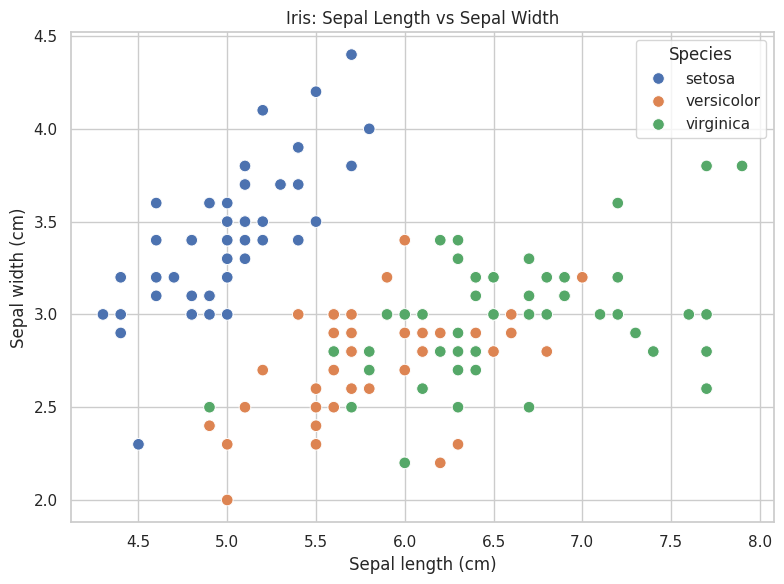

In [4]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=iris_df,
    x="sepal length (cm)",
    y="sepal width (cm)",
    hue="species",
    s=70,
)
plt.title("Iris: Sepal Length vs Sepal Width")
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.legend(title="Species")
plt.tight_layout()
plt.show()

再观察全部特征两两之间的关系。对角线显示单个特征的分布，非对角线显示两个特征之间的散点关系。

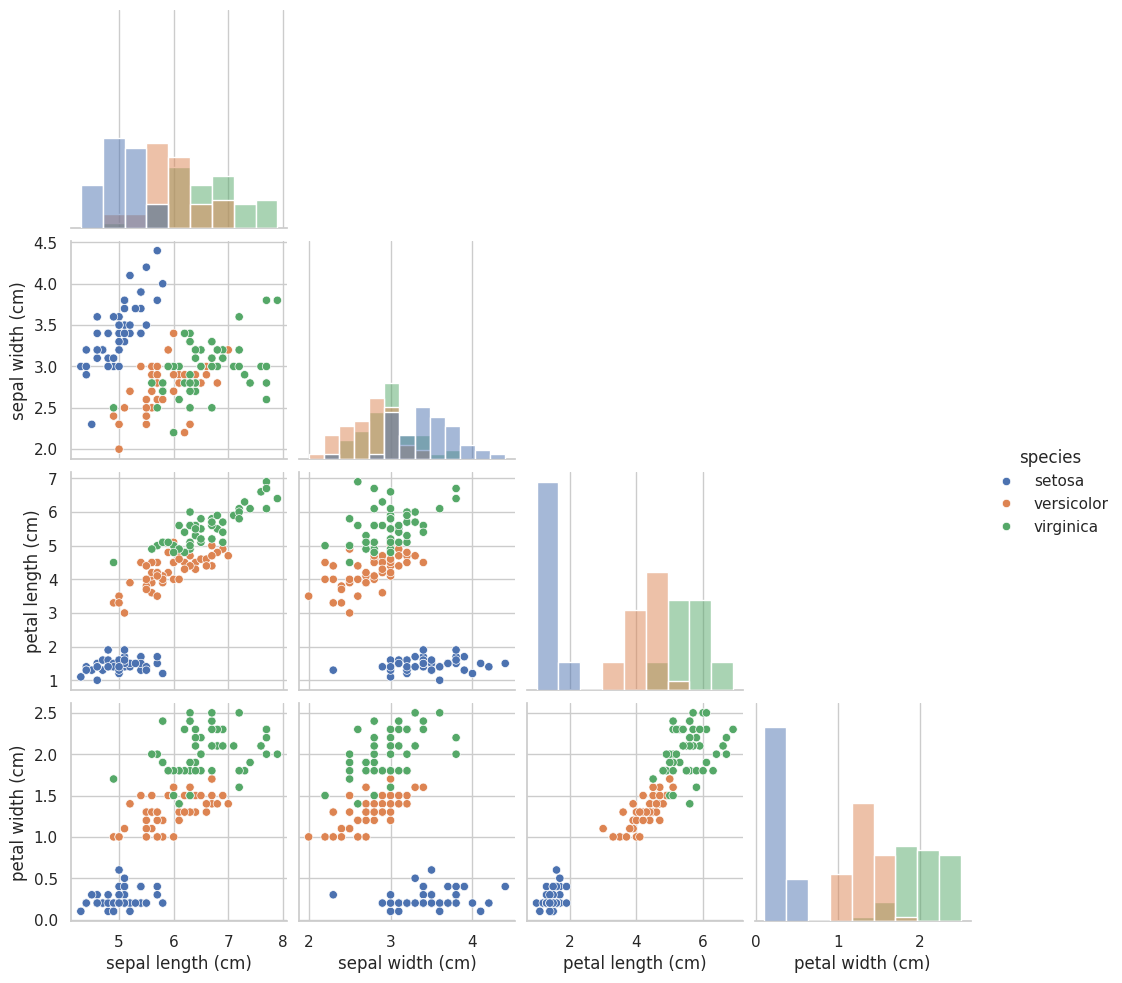

In [5]:
sns.pairplot(
    iris_df,
    vars=iris.feature_names,
    hue="species",
    diag_kind="hist",
    corner=True,
)
plt.show()

### 观察提示

- 不同类别在部分特征空间中会形成相对明显的聚类。
- 花瓣长度和花瓣宽度通常对类别区分较有帮助。
- 仍可能存在类别之间重叠的区域，因此需要模型综合多个特征进行判断。

可视化帮助我们理解数据，但不能代替训练集之外的数据评估。

## 5. 划分训练集与测试集

模型不能只在训练时见过的数据上评估，否则无法客观判断它对新数据的泛化能力。

- **训练集（Training Set）**：用于让模型学习特征与标签之间的关系。
- **测试集（Test Set）**：训练过程中不参与模型拟合，最后用于评估模型面对新样本时的表现。

本案例使用 80% 数据作为训练集，20% 作为测试集。

`stratify=y` 表示按照标签类别进行分层抽样，使训练集和测试集尽量保持与原数据集相近的类别比例。

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("训练集特征形状：", X_train.shape)
print("测试集特征形状：", X_test.shape)
print("训练集标签形状：", y_train.shape)
print("测试集标签形状：", y_test.shape)

print("\n训练集中各类别的样本数：")
display(y_train.value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))))

print("测试集中各类别的样本数：")
display(y_test.value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))))

训练集特征形状： (120, 4)
测试集特征形状： (30, 4)
训练集标签形状： (120,)
测试集标签形状： (30,)

训练集中各类别的样本数：


target
setosa        40
versicolor    40
virginica     40
Name: count, dtype: int64

测试集中各类别的样本数：


target
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64

## 6. 特征工程：特征标准化

### 6.1 为什么需要特征缩放？

KNN 是一种基于距离进行判断的算法。若不同特征的数值范围差异较大，数值范围较大的特征可能对距离产生更大的影响。

例如，KNN 常使用欧氏距离：

\[
d(x, y) = \sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
\]

因此，在 KNN 中通常需要考虑对特征进行缩放。

### 6.2 归一化与标准化的区别

**归一化（Min-Max Scaling）**

将特征缩放到指定区间，默认通常是 \([0,1]\)：

\[
x' = \frac{x-x_{min}}{x_{max}-x_{min}}
\]

它容易受到极端值影响。

**标准化（Standardization）**

将特征转换为均值约为 0、标准差约为 1 的尺度：

\[
x' = \frac{x-\mu}{\sigma}
\]

标准化不要求数据服从正态分布。它只是对特征进行中心化和尺度调整。

本案例使用 `StandardScaler`。

### 6.3 正确执行标准化：先 fit 训练集，再 transform 测试集

- `fit()`：从数据中学习缩放所需的统计量，例如均值和标准差。
- `transform()`：使用已经学习到的统计量转换数据。
- `fit_transform()`：先学习统计量，再转换数据。

**非常重要：不能先对全部数据 fit 再切分。** 否则测试集的信息会参与预处理参数的计算，造成数据泄漏（Data Leakage）。

因此，应该只在训练集上 `fit_transform()`，测试集只调用 `transform()`。

In [7]:
# 创建标准化对象
scaler = StandardScaler()

# 只使用训练集学习均值和标准差，并转换训练集
X_train_scaled = scaler.fit_transform(X_train)

# 使用训练集得到的均值和标准差转换测试集
X_test_scaled = scaler.transform(X_test)

print("标准化后训练集的特征均值（接近 0）：")
print(np.round(X_train_scaled.mean(axis=0), 3))

print("\n标准化后训练集的特征标准差（接近 1）：")
print(np.round(X_train_scaled.std(axis=0), 3))

标准化后训练集的特征均值（接近 0）：
[-0. -0.  0.  0.]

标准化后训练集的特征标准差（接近 1）：
[1. 1. 1. 1.]


## 7. 创建并训练 KNN 分类模型

### 7.1 KNN 算法的基本思想

KNN（K-Nearest Neighbors，K-近邻）是一种经典的监督学习算法。

对于一个待预测样本，KNN 会：

1. 计算它与训练集中样本之间的距离。
2. 找出距离最近的 K 个邻居。
3. 统计这 K 个邻居所属的类别。
4. 将数量最多的类别作为预测结果（分类任务的常见做法）。

### 7.2 设置 K 值

本案例先使用 `n_neighbors=3`，也就是参考最近的 3 个邻居。

K 值较小时，模型容易受到个别样本影响；K 值较大时，决策边界可能变得更平滑。合适的 K 值通常需要通过验证方法选择。

In [8]:
# 创建 KNN 分类器
knn_model = KNeighborsClassifier(n_neighbors=3)

# 使用标准化后的训练数据训练模型
knn_model.fit(X_train_scaled, y_train)

print("KNN 模型训练完成。")

KNN 模型训练完成。


## 8. 使用模型进行预测

使用训练好的模型，对测试集进行预测。

`predict()` 接收特征数据，返回模型预测的类别标签。

In [9]:
# 对测试集进行预测
y_pred = knn_model.predict(X_test_scaled)

# 对比前 10 条真实标签和预测标签
prediction_result = pd.DataFrame({
    "真实类别": [iris.target_names[i] for i in y_test.iloc[:10]],
    "预测类别": [iris.target_names[i] for i in y_pred[:10]],
})

display(prediction_result)

,真实类别,预测类别
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


## 9. 模型评估

模型评估用于衡量分类模型的预测效果。本案例使用准确率、混淆矩阵和分类报告。

### 9.1 准确率（Accuracy）

\[
Accuracy = \frac{预测正确的样本数量}{测试集样本总数}
\]

注意区分训练集准确率和测试集准确率：

- 训练集准确率：模型在训练数据上的表现。
- 测试集准确率：模型在未参与训练的数据上的表现，更适合用于初步衡量泛化能力。

只报告训练集准确率可能会掩盖过拟合问题。

In [10]:
# 分别计算训练集和测试集准确率
train_accuracy = knn_model.score(X_train_scaled, y_train)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"训练集准确率：{train_accuracy:.4f}")
print(f"测试集准确率：{test_accuracy:.4f}")

训练集准确率：0.9583
测试集准确率：0.9333


### 9.2 混淆矩阵（Confusion Matrix）

混淆矩阵用于统计真实类别和预测类别之间的对应关系。

- 行表示真实类别。
- 列表示预测类别。
- 对角线上的数值表示预测正确的数量。
- 非对角线上的数值表示被错误分类的数量。

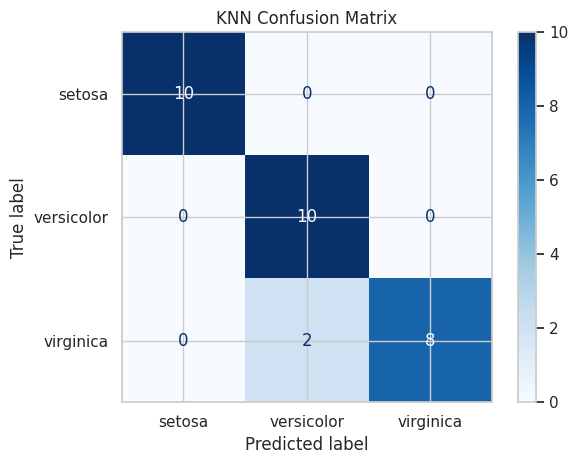

In [11]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names,
)
disp.plot(cmap="Blues", values_format="d")
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

### 9.3 分类报告（Classification Report）

分类报告提供每个类别的：

- **Precision（精确率）**：被预测为某类别的样本中，真实属于该类别的比例。
- **Recall（召回率）**：真实属于某类别的样本中，被正确找出的比例。
- **F1-score**：精确率和召回率的调和平均。
- **Support**：测试集中该类别真实样本的数量。

In [12]:
report = classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report).T
display(report_df.round(3))

,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,10.000
versicolor,0.833,1.000,0.909,10.000
virginica,1.000,0.800,0.889,10.000
accuracy,0.933,0.933,0.933,0.933
macro avg,0.944,0.933,0.933,30.000
weighted avg,0.944,0.933,0.933,30.000


## 10. 对一条新数据进行预测

在实际使用中，我们往往希望模型能够预测一条从未参与训练的新数据。

下面构造一条示例数据，四个数值依次对应：

1. 花萼长度（cm）
2. 花萼宽度（cm）
3. 花瓣长度（cm）
4. 花瓣宽度（cm）

**注意：** 新数据必须使用与训练数据完全相同的特征顺序，并且必须调用训练阶段已经 fit 好的 `scaler` 进行转换，不能重新 fit 一个标准化器。

In [13]:
# 构造一条新样本
new_flower = pd.DataFrame(
    [[7.4, 2.5, 3.9, 1.6]],
    columns=iris.feature_names,
)

# 使用训练阶段的标准化器转换新样本
new_flower_scaled = scaler.transform(new_flower)

# 进行类别预测
predicted_label = knn_model.predict(new_flower_scaled)[0]
predicted_species = iris.target_names[predicted_label]

print("新样本的输入特征：")
display(new_flower)

print("模型预测的类别：", predicted_species)

新样本的输入特征：


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,7.4,2.5,3.9,1.6


模型预测的类别： versicolor


## 11. 扩展：使用交叉验证选择更合适的 K 值

前面直接设置了 `n_neighbors=3`。但 K=3 是否一定是最佳选择？不一定。

可以在训练集上使用交叉验证，比较不同 K 值的表现，再选择交叉验证准确率较高的参数。

### 为什么这里使用 Pipeline？

`Pipeline` 将标准化和 KNN 模型串联起来。在交叉验证的每一轮中，标准化器只会在当前轮的训练折上 fit，再转换验证折，从而避免验证数据的信息泄漏到预处理过程。

In [14]:
# 建立“标准化 + KNN”的流水线
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

# 设置交叉验证策略
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# 搜索 K = 1 到 15
param_grid = {
    "knn__n_neighbors": list(range(1, 16))
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1,
)

# 只在训练集上进行参数搜索
grid_search.fit(X_train, y_train)

print("交叉验证选择的最佳参数：", grid_search.best_params_)
print(f"最佳交叉验证平均准确率：{grid_search.best_score_:.4f}")

交叉验证选择的最佳参数： {'knn__n_neighbors': 3}
最佳交叉验证平均准确率：0.9667


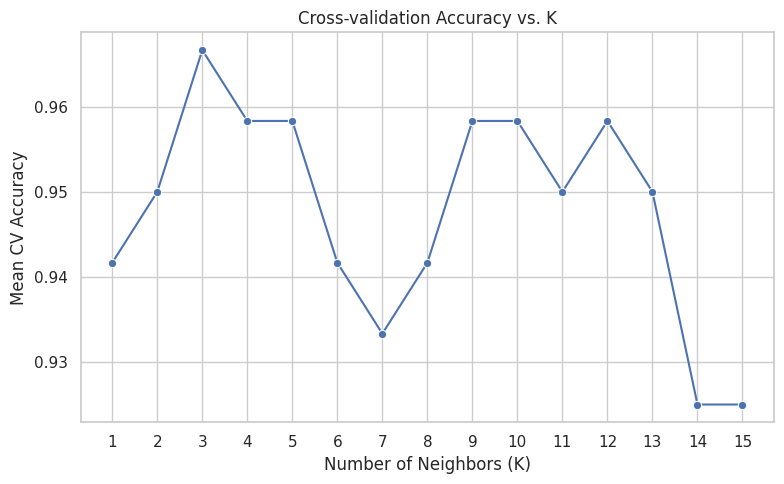

In [15]:
# 查看不同 K 值对应的交叉验证平均准确率
cv_results = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=cv_results,
    x="param_knn__n_neighbors",
    y="mean_test_score",
    marker="o",
)
plt.title("Cross-validation Accuracy vs. K")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.xticks(range(1, 16))
plt.tight_layout()
plt.show()

### 11.1 在测试集上评估调参后的模型

参数搜索只使用训练集完成。确定最佳参数后，再使用从未参与调参的测试集进行最终评估。

In [16]:
best_knn_model = grid_search.best_estimator_

best_test_pred = best_knn_model.predict(X_test)
best_test_accuracy = accuracy_score(y_test, best_test_pred)

print("调参前（K=3）的测试集准确率：", f"{test_accuracy:.4f}")
print("调参后的测试集准确率：", f"{best_test_accuracy:.4f}")
print("调参后的最佳 K 值：", grid_search.best_params_["knn__n_neighbors"])

调参前（K=3）的测试集准确率： 0.9333
调参后的测试集准确率： 0.9333
调参后的最佳 K 值： 3


## 12. 项目总结

本案例完成了一个完整的 KNN 鸢尾花分类流程：

| 环节 | 本案例使用的方法 | 目的 |
|---|---|---|
| 数据加载 | `load_iris()` | 获取特征和标签 |
| 数据探索 | Pandas、Seaborn | 了解数据结构和分布 |
| 数据集划分 | `train_test_split()` | 分离训练数据和测试数据 |
| 特征工程 | `StandardScaler()` | 统一特征尺度 |
| 模型训练 | `KNeighborsClassifier()` | 学习分类规则 |
| 模型评估 | Accuracy、混淆矩阵、分类报告 | 检查分类效果 |
| 参数优化 | `GridSearchCV`、交叉验证 | 搜索更合适的 K 值 |

### 需要记住的几个关键点

1. **特征和标签不同：** `X` 是模型输入，`y` 是希望模型预测的目标。
2. **先划分，再预处理：** 标准化器只在训练集上 fit，测试集和新数据只 transform。
3. **训练集与测试集准确率不同：** 测试集更能反映模型对未见数据的表现。
4. **K 值需要选择：** 可以通过交叉验证比较不同参数，而不是只凭经验决定。
5. **测试集要留到最后：** 不要反复利用测试集挑选模型参数，否则测试集就不再是独立评估数据。

### 下一步可以继续学习

- 比较 KNN、决策树、逻辑回归和支持向量机（SVM）。
- 学习交叉验证、混淆矩阵、精确率、召回率和 F1-score。
- 尝试调整测试集比例、K 值和距离度量方式。
- 尝试把模型保存下来，并在独立 Python 脚本中加载和预测。

---

**案例结论：** 鸢尾花分类是一个适合入门的监督学习案例。它的数据规模小、特征含义直观，能够帮助初学者理解从数据准备到模型评估的基本工作流。